# Compare boosting families

Last time, I tried logistic regression with L1 regularization. This time, I want to see whether boosting models can rank patients by readmission risk more accurately. I compare six boosting models using the same features and validation splits.

I use the same five validation splits for every trial so the scores are comparable. After comparing the models, I fit the chosen model on all labeled stays to predict readmission risk for the test stays.

## Import Libraries

In [1]:
from pathlib import Path
import importlib.util
import subprocess
import sys
import json
import copy
import re
from time import perf_counter

packages = {'numpy': 'numpy', 'pandas': 'pandas>=2.2', 'sklearn': 'scikit-learn>=1.5',
            'matplotlib': 'matplotlib', 'threadpoolctl': 'threadpoolctl',
            'xgboost': 'xgboost>=2', 'lightgbm': 'lightgbm>=4', 'catboost': 'catboost>=1.2'}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', *missing], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score, f1_score, average_precision_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

plt.style.use('seaborn-v0_8-whitegrid')
SEED = 42
JOBS = 4
STAGE = 6
STAGE_NAME = '06_boosting_baseline'
paths = ['/kaggle/input/competitions/machine-learning-fall-26-challenge-1-iba-karachi/',
         '/kaggle/input/machine-learning-fall-26-challenge-1-iba-karachi/',
         'kaggle/input/dataset/', '../kaggle/input/dataset/', '../../kaggle/input/dataset/', './']
DATA_DIR = next((Path(p) for p in paths if (Path(p) / 'train.csv').exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Dataset not found. Check the dataset folder.')

OUTPUT_DIR = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path('extra/outputs/boosting_progression') / STAGE_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Data:', DATA_DIR)
print('Results:', OUTPUT_DIR)


Data: /kaggle/input/competitions/machine-learning-fall-26-challenge-1-iba-karachi
Results: /kaggle/working


## Load Dataset

In [2]:
quality = {}

def read_csv(name):
    # No row limit: read the whole source table.
    table = pd.read_csv(DATA_DIR / f'{name}.csv', low_memory=False)
    quality[name + '_rows_read'] = len(table)
    duplicates = int(table.duplicated().sum())
    quality[name + '_duplicates_removed'] = duplicates
    print(f'{name}: {len(table):,} rows; {duplicates:,} exact duplicates')
    return table.drop_duplicates().copy()

train = read_csv('train')
test = read_csv('test')
encounters = read_csv('index_encounters')
patients = read_csv('patients')
hospitals = read_csv('hospitals')
diagnoses = read_csv('diagnoses')
icd_lookup = read_csv('icd10_lookup')
procedures = read_csv('procedures')
labs = read_csv('lab_results')
vitals = read_csv('vitals')
meds = read_csv('medications')
transfers = read_csv('unit_transfers')
prior = read_csv('prior_utilization')
planning = read_csv('discharge_planning')
assert encounters.encounter_id.is_unique and encounters.patient_id.is_unique
assert patients.patient_id.is_unique and hospitals.hospital_id.is_unique
assert planning.encounter_id.is_unique
assert train.encounter_id.is_unique and test.encounter_id.is_unique
assert not set(train.encounter_id) & set(test.encounter_id)


train: 76,975 rows; 0 exact duplicates
test: 32,812 rows; 0 exact duplicates
index_encounters: 109,787 rows; 0 exact duplicates
patients: 109,787 rows; 0 exact duplicates
hospitals: 40 rows; 0 exact duplicates
diagnoses: 451,976 rows; 902 exact duplicates
icd10_lookup: 82 rows; 0 exact duplicates
procedures: 19,547 rows; 0 exact duplicates
lab_results: 1,668,783 rows; 3,331 exact duplicates
vitals: 2,267,367 rows; 2,265 exact duplicates
medications: 447,278 rows; 893 exact duplicates
unit_transfers: 211,097 rows; 0 exact duplicates
prior_utilization: 714,062 rows; 1,284 exact duplicates
discharge_planning: 97,552 rows; 0 exact duplicates


Each target row is one hospital stay. Event tables have many rows per stay and are summarized before joining. All rows are read; missing optional records remain missing or become zero observed events.

## Target Distribution

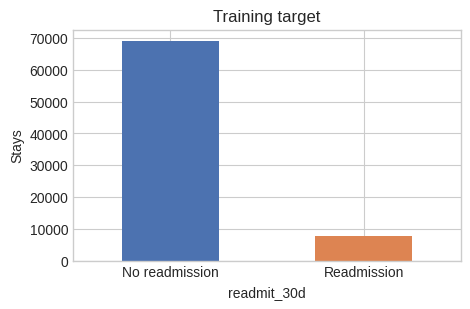

In [3]:
train.readmit_30d.value_counts().reindex([0, 1]).plot.bar(figsize=(5, 3), color=['#4C72B0', '#DD8452'])
plt.xticks([0, 1], ['No readmission', 'Readmission'], rotation=0)
plt.ylabel('Stays')
plt.title('Training target')
plt.show()


## Data Cleaning

In [4]:
def clean_text(series):
    result = series.astype('string').str.strip().str.upper()
    result = result.replace({'?': pd.NA, 'UNKNOWN': pd.NA, 'U': pd.NA,
                             'NOT AVAILABLE': pd.NA, 'NOT MAPPED': pd.NA, '': pd.NA})
    return result.astype(object).where(result.notna(), np.nan)

for table, columns in [
    (patients, ['insurance_type', 'race_ethnicity', 'sex', 'language', 'marital_status']),
    (encounters, ['admission_type', 'admission_source', 'service_line', 'discharge_disposition', 'attending_specialty']),
    (hospitals, ['urban_rural', 'ownership']),
]:
    for column in columns:
        table[column] = clean_text(table[column])
encounters['admit_dt'] = pd.to_datetime(encounters.admit_dt, format='mixed', errors='coerce')
encounters['discharge_dt'] = pd.to_datetime(encounters.discharge_dt, format='mixed', errors='coerce')
assert encounters.admit_dt.notna().all() and encounters.discharge_dt.ge(encounters.admit_dt).all()
patients.loc[patients.birth_year.le(1900), 'birth_year'] = np.nan
patients.loc[~patients.deprivation_index.between(0, 100), 'deprivation_index'] = np.nan
planning['home_health_referral'] = clean_text(planning.home_health_referral).map({'Y': 1., 'N': 0.})
planning['education_done'] = clean_text(planning.education_done).map({'YES': 1., 'NO': 0.})

admit_by_stay = encounters.set_index('encounter_id').admit_dt
discharge_by_stay = encounters.set_index('encounter_id').discharge_dt

def within_stay(table, column, fmt, date_only=False):
    when = pd.to_datetime(table[column], format=fmt, errors='coerce')
    start = table.encounter_id.map(admit_by_stay)
    end = table.encounter_id.map(discharge_by_stay)
    if date_only:
        when, start, end = when.dt.normalize(), start.dt.normalize(), end.dt.normalize()
    keep = when.ge(start) & when.le(end)
    quality[column + '_outside_stay_or_invalid'] = int((~keep).sum())
    result = table.loc[keep].copy()
    result[column] = when.loc[keep]
    return result

labs = within_stay(labs, 'collected_dt', '%Y-%m-%d %H:%M:%S')
vitals = within_stay(vitals, 'charttime', '%m/%d/%Y %H:%M')
meds = within_stay(meds, 'start_dt', '%Y%m%d', date_only=True)
procedures = within_stay(procedures, 'proc_dt', '%d-%b-%Y', date_only=True)
patient_admit = encounters.set_index('patient_id').admit_dt.dt.normalize()
prior['days_before'] = (prior.patient_id.map(patient_admit) - pd.to_datetime(prior.visit_dt, errors='coerce')).dt.days
quality['prior_not_before_admission'] = int((~prior.days_before.gt(0)).sum())
prior = prior.loc[prior.days_before.gt(0)].copy()


Exact duplicate rows are removed, category spelling is normalized, and dates are parsed. Events outside the stay are excluded. Unknown values remain unknown.

## Diagnosis Codes

In [5]:
print('Lookup match before cleaning:', diagnoses.icd10_code.isin(icd_lookup.icd10_code).mean().round(3))

def clean_icd(code):
    code = str(code).strip().upper().replace('.', '')
    return code[:3] + '.' + code[3:] if len(code) > 3 else code

diagnoses['icd10_code'] = diagnoses.icd10_code.map(clean_icd)
diagnoses = diagnoses.merge(icd_lookup[['icd10_code', 'chapter', 'chronic_flag']], on='icd10_code', how='left')
print('Lookup match after cleaning: ', diagnoses.chapter.notna().mean().round(3))


Lookup match before cleaning: 0.725
Lookup match after cleaning:  1.0


## Lab Units

In [6]:
conversions = {
    'Albumin': {'g/dL': 1, 'g/L': .1}, 'Hemoglobin': {'g/dL': 1, 'g/L': .1},
    'Creatinine': {'mg/dL': 1, 'umol/L': 1 / 88.4}, 'Glucose': {'mg/dL': 1, 'mmol/L': 18.0182},
    'Sodium': {'mmol/L': 1}, 'Potassium': {'mmol/L': 1}, 'Bun': {'mg/dL': 1},
    'Bnp': {'pg/mL': 1}, 'Hba1C': {'%': 1}, 'Inr': {'ratio': 1},
    'Lactate': {'mmol/L': 1}, 'Troponin_I': {'ng/mL': 1}, 'Wbc': {'10^3/uL': 1},
}
limits = {'Sodium': (80, 200), 'Potassium': (1, 10), 'Glucose': (10, 1500),
          'Creatinine': (.05, 30), 'Bun': (0, 300), 'Hemoglobin': (1, 30),
          'Wbc': (.1, 200), 'Albumin': (.1, 10), 'Lactate': (0, 40),
          'Troponin_I': (0, 100), 'Bnp': (0, 100000), 'Hba1C': (2, 25), 'Inr': (.1, 20)}
labs['value_std'] = np.nan
for name, units in conversions.items():
    rows = labs.lab_name.eq(name)
    labs.loc[rows, 'value_std'] = pd.to_numeric(labs.loc[rows, 'value'], errors='coerce') * labs.loc[rows, 'unit'].map(units)
    low, high = limits[name]
    invalid = rows & labs.value_std.notna() & ~labs.value_std.between(low, high)
    quality[name + '_extreme_lab_values'] = int(invalid.sum())
    labs.loc[invalid, 'value_std'] = np.nan
quality['lab_values_unknown_unit'] = int(sum((labs.lab_name.eq(name) & ~labs.unit.isin(units)).sum() for name, units in conversions.items()))
display(labs.groupby('lab_name').value_std.agg(['count', 'median', 'min', 'max']).round(2))


,count,median,min,max
lab_name,,,,
Albumin,55448,3.50,1.00,5.50
Bnp,18440,687.00,7.00,34230.00
Bun,185627,21.00,4.00,300.00
Creatinine,210474,1.18,0.34,29.70
Glucose,261582,137.00,46.00,1500.00
Hba1C,16971,7.40,3.80,9.80
Hemoglobin,190494,12.10,4.00,18.70
Inr,16068,1.15,0.82,9.30
Lactate,34622,2.40,0.40,40.00


Units are converted before calculating summaries. Missing units stay unknown. Extreme readings are screened with broad engineering bounds; large values are not automatically divided by ten. These are data-processing assumptions, not clinical rules.

## Vital Signs

In [7]:
vitals['value'] = pd.to_numeric(vitals.value, errors='coerce')
fahrenheit = vitals.vital_type.eq('TEMP') & vitals.value.between(80, 115)
vitals.loc[fahrenheit, 'value'] = (vitals.loc[fahrenheit, 'value'] - 32) / 1.8
quality['temperature_values_converted'] = int(fahrenheit.sum())
vital_limits = {'HR': (20, 250), 'SBP': (40, 300), 'DBP': (20, 200),
                'RR': (4, 80), 'SPO2': (50, 100), 'TEMP': (30, 43)}
for name, (low, high) in vital_limits.items():
    invalid = vitals.vital_type.eq(name) & vitals.value.notna() & ~vitals.value.between(low, high)
    quality[name + '_invalid_vital_values'] = int(invalid.sum())
    vitals.loc[invalid, 'value'] = np.nan
display(vitals.groupby('vital_type').value.agg(['count', 'median', 'min', 'max']).round(2))


,count,median,min,max
vital_type,,,,
DBP,377290,79.0,28.0,130.0
HR,376974,80.0,29.0,147.0
RR,377355,18.0,7.0,32.0
SBP,377527,129.0,57.0,210.0
SPO2,377567,96.0,86.0,100.0
TEMP,377655,36.9,35.2,38.5


## Patient and Stay Features

In [8]:
df = (encounters
      .merge(patients, on='patient_id', how='left', validate='many_to_one')
      .merge(hospitals, on='hospital_id', how='left', validate='many_to_one')
      .merge(planning, on='encounter_id', how='left', validate='many_to_one'))

df['age'] = df.admit_dt.dt.year - df.birth_year
df['los_days'] = (df.discharge_dt - df.admit_dt).dt.total_seconds() / 86400

counts = {
    'n_diagnoses': diagnoses.groupby('encounter_id').size(),
    'n_procedures': procedures.groupby('encounter_id').size(),
    'n_labs': labs.groupby('encounter_id').size(),
    'n_labs_abnormal': labs[labs.abnormal_flag.isin(['H', 'L'])].groupby('encounter_id').size(),
    'n_vitals': vitals.groupby('encounter_id').size(),
    'n_medications': meds.groupby('encounter_id').size(),
    'n_meds_at_discharge': meds[meds.continued_at_discharge == 1].groupby('encounter_id').size(),
    'n_unit_transfers': transfers.groupby('encounter_id').size(),
    'n_icu_stays': transfers[transfers.unit == 'ICU'].groupby('encounter_id').size(),
}
for name, s in counts.items():
    df[name] = df.encounter_id.map(s).fillna(0)

prior_counts = pd.crosstab(prior.patient_id, prior.visit_type).add_prefix('prior_')
df = df.merge(prior_counts, left_on='patient_id', right_index=True, how='left', validate='many_to_one')
df[prior_counts.columns] = df[prior_counts.columns].fillna(0)

base_num = ['age', 'los_days', 'deprivation_index', 'bed_size', 'teaching_flag',
            'n_diagnoses', 'n_procedures', 'n_labs', 'n_labs_abnormal', 'n_vitals',
            'n_medications', 'n_meds_at_discharge', 'n_unit_transfers', 'n_icu_stays',
            'prior_ED', 'prior_IP', 'prior_OP',
            'followup_scheduled_days', 'home_health_referral', 'med_reconciliation_done', 'education_done']
base_cat = ['hospital_id', 'admission_type', 'admission_source', 'service_line', 'discharge_disposition',
            'attending_specialty', 'sex', 'race_ethnicity', 'language', 'marital_status',
            'insurance_type', 'urban_rural', 'ownership']


## Stay Timing

In [9]:
stay = pd.DataFrame(index=df.encounter_id)
stay['admit_weekend'] = (df.admit_dt.dt.dayofweek >= 5).astype(int).values
stay['discharge_weekend'] = (df.discharge_dt.dt.dayofweek >= 5).astype(int).values
stay['discharge_hour'] = df.discharge_dt.dt.hour.values
stay['admit_weight_kg'] = df.admit_weight_kg.values
stay['followup_within_7d'] = df.followup_scheduled_days.le(7).where(df.followup_scheduled_days.notna()).astype(float).values


## Diagnosis Features

In [10]:
dx = pd.DataFrame({
    'n_dx_chronic': diagnoses.groupby('encounter_id').chronic_flag.sum(),
    'n_dx_unique': diagnoses.groupby('encounter_id').icd10_code.nunique(),
    'n_dx_chapters': diagnoses.groupby('encounter_id').chapter.nunique(),
    'n_dx_hospital_acquired': diagnoses[diagnoses.present_on_admission == 'N'].groupby('encounter_id').size(),
})
dx_chapter = pd.crosstab(diagnoses.encounter_id, diagnoses.chapter).add_prefix('chapter_')
dx_code = pd.crosstab(diagnoses.encounter_id, diagnoses.icd10_code).clip(upper=1).add_prefix('dx_')

primary = diagnoses[diagnoses.is_primary == 1].drop_duplicates('encounter_id').set_index('encounter_id')
df['primary_dx'] = df.encounter_id.map(primary.icd10_code)
df['primary_chapter'] = df.encounter_id.map(primary.chapter)
dx['primary_chronic'] = primary.chronic_flag

dx = dx.join(dx_chapter).join(dx_code)
dx.shape


(109787, 103)

## Procedure Features

In [11]:
proc = pd.crosstab(procedures.encounter_id, procedures.code).add_prefix('proc_')
proc.shape


(18800, 15)

## Lab Features

In [12]:
labs = labs.sort_values(['encounter_id', 'collected_dt'])
labs['abnormal'] = labs.abnormal_flag.isin(['H', 'L']).astype(int)

lab_stats = labs.groupby(['encounter_id', 'lab_name']).value_std.agg(['first', 'last', 'min', 'max', 'mean']).unstack()
lab_stats.columns = [f'lab_{lab}_{stat}' for stat, lab in lab_stats.columns]
lab_abnormal = labs.groupby(['encounter_id', 'lab_name']).abnormal.sum().unstack().add_prefix('lab_abnormal_')

lab = lab_stats.join(lab_abnormal)
lab.shape


(109784, 78)

## Vital Features

In [13]:
vitals = vitals.sort_values(['encounter_id', 'charttime'])
vit_stats = vitals.groupby(['encounter_id', 'vital_type']).value.agg(['first', 'last', 'min', 'max', 'mean', 'std']).unstack()
vit_stats.columns = [f'vital_{v}_{stat}' for stat, v in vit_stats.columns]

flags = pd.DataFrame({
    'encounter_id': vitals.encounter_id,
    'n_tachycardia': (vitals.vital_type == 'HR') & (vitals.value > 100),
    'n_hypotension': (vitals.vital_type == 'SBP') & (vitals.value < 90),
    'n_hypoxia': (vitals.vital_type == 'SPO2') & (vitals.value < 90),
    'n_fever': (vitals.vital_type == 'TEMP') & (vitals.value > 38),
    'n_tachypnea': (vitals.vital_type == 'RR') & (vitals.value > 22),
}).groupby('encounter_id').sum()

vit = vit_stats.join(flags)
vit.shape


(109787, 41)

## Medication Features

In [14]:
continued = meds[meds.continued_at_discharge == 1]
med = (pd.crosstab(meds.encounter_id, meds.drug_class).add_prefix('med_')
       .join(pd.crosstab(continued.encounter_id, continued.drug_class).add_prefix('med_continued_'))
       .join(pd.crosstab(meds.encounter_id, meds.route).add_prefix('route_')))
med['n_drug_classes'] = meds.groupby('encounter_id').drug_class.nunique()
med.shape


(107628, 49)

## Unit Transfers

In [15]:
entry = pd.to_datetime(transfers.in_dt, format='mixed', errors='coerce')
exit_ = pd.to_datetime(transfers.out_dt, format='mixed', errors='coerce')
start = pd.concat([entry, transfers.encounter_id.map(admit_by_stay)], axis=1).max(axis=1)
end = pd.concat([exit_, transfers.encounter_id.map(discharge_by_stay)], axis=1).min(axis=1)
valid = entry.notna() & exit_.notna() & end.ge(start)
quality['invalid_transfer_intervals'] = int((~valid).sum())
transfers = transfers.loc[valid].copy()
transfers['hours'] = (end[valid] - start[valid]).dt.total_seconds() / 3600
unit = transfers.pivot_table(index='encounter_id', columns='unit', values='hours', aggfunc='sum').add_prefix('hours_')
unit.shape


(109787, 4)

## Prior Utilisation

In [16]:
visits = prior.merge(encounters[['patient_id', 'admit_dt']], on='patient_id')
visits['days_before'] = (visits.admit_dt.dt.normalize() - pd.to_datetime(visits.visit_dt)).dt.days

util = pd.DataFrame(index=visits.patient_id.unique())
for window in [30, 90, 180, 365]:
    recent = visits[visits.days_before <= window]
    util = util.join(pd.crosstab(recent.patient_id, recent.visit_type).add_prefix('prior_').add_suffix(f'_{window}d'))
util = util.join(visits.groupby(['patient_id', 'visit_type']).days_before.min().unstack().add_prefix('days_since_last_'))
util.shape


(109222, 15)

## Combine Features

In [17]:
count_like = [dx_chapter.columns, dx_code.columns, proc.columns, lab_abnormal.columns, flags.columns,
              med.columns.drop('n_drug_classes'), unit.columns,
              [c for c in util.columns if c.startswith('prior_')]]
count_like = [c for group in count_like for c in group] + ['n_dx_hospital_acquired']

features = (stay.join(dx).join(proc).join(lab).join(vit).join(med).join(unit)
            .reset_index().rename(columns={'index': 'encounter_id'}))
features = features.merge(df[['encounter_id', 'patient_id'] + base_num + base_cat + ['primary_dx', 'primary_chapter']],
                          on='encounter_id', how='left')
features = features.merge(util, left_on='patient_id', right_index=True, how='left')
features[count_like] = features[count_like].fillna(0)

cat_cols = base_cat + ['primary_dx', 'primary_chapter']
num_cols = [c for c in features.columns if c not in cat_cols + ['encounter_id', 'patient_id']]
# Keep the fixed feature definitions; missing-value handling is fitted inside each CV fold.

X = train[['encounter_id']].merge(features, on='encounter_id', how='left')
y = train.readmit_30d
X_test = test[['encounter_id']].merge(features, on='encounter_id', how='left')

print(X.shape, X_test.shape)
print('Numeric features:', len(num_cols), '| Categorical features:', len(cat_cols))
assert features.encounter_id.is_unique
assert len(X) == len(train) and len(X_test) == len(test)
all_features = features.set_index('encounter_id')[num_cols + cat_cols].copy()
all_features = all_features.replace([np.inf, -np.inf], np.nan)
y = pd.Series(train.readmit_30d.to_numpy(), index=train.encounter_id, name='readmit_30d')
assert all_features.index.is_unique and y.index.is_unique
assert set(y.index) | set(test.encounter_id) == set(all_features.index)
print('Inputs:', all_features.shape[1], '| labeled stays:', len(y))


(76975, 348) (32812, 348)
Numeric features: 331 | Categorical features: 15
Inputs: 346 | labeled stays: 76975


## Missing Values

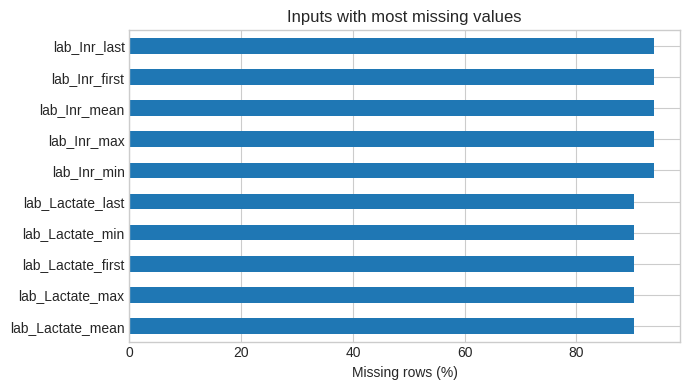

In [18]:
all_features.isna().mean().sort_values().tail(10).mul(100).plot.barh(figsize=(7, 4))
plt.xlabel('Missing rows (%)')
plt.title('Inputs with most missing values')
plt.tight_layout()
plt.show()


## Feature Comparison

In [19]:
def make_feature_views(frame):
    # Compare the same stays using fewer repeated measurement summaries.
    repeated = [c for c in frame if c.startswith(('lab_', 'vital_'))
                and c.rsplit('_', 1)[-1] in ['first', 'last', 'min', 'max', 'std']]
    compact = frame.drop(columns=repeated)
    detailed_codes = [c for c in compact if c.startswith(('dx_', 'proc_'))]
    calendar = [c for c in ['admit_weekend', 'discharge_weekend', 'discharge_hour', 'primary_dx'] if c in compact]
    focused = compact.drop(columns=list(dict.fromkeys(detailed_codes + calendar)))
    return {'full': frame, 'compact': compact, 'focused': focused}


In [20]:
views = {'full': all_features}
BASE_VIEW = 'full'


In [21]:
display(pd.DataFrame({'View': list(views), 'Input features': [len(frame.columns) for frame in views.values()]}))


,View,Input features
0,full,346


## Models and Preprocessing

Only boosting estimators are fitted. Numbers are median-filled with missing indicators for models needing encoded inputs. Categories are one-hot encoded there; LightGBM and CatBoost use native categories. Every learned preprocessing step and any feature selection is fitted on training folds only.

In [22]:
def new_model(spec):
    parameters = copy.deepcopy(spec['params'])
    family = spec['family']
    if family == 'AdaBoost':
        depth = parameters.pop('tree_depth', 1)
        return AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=depth,
            min_samples_leaf=100, max_features=.2, random_state=SEED), random_state=SEED, **parameters)
    if family == 'Gradient Boosting':
        return GradientBoostingClassifier(random_state=SEED, **parameters)
    if family == 'Histogram Gradient Boosting':
        return HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **parameters)
    if family == 'XGBoost':
        return XGBClassifier(objective='binary:logistic', eval_metric='auc', tree_method='hist',
                             n_jobs=JOBS, random_state=SEED, **parameters)
    if family == 'LightGBM':
        return LGBMClassifier(verbosity=-1, n_jobs=JOBS, random_state=SEED, **parameters)
    if family == 'CatBoost':
        return CatBoostClassifier(loss_function='Logloss', eval_metric='AUC', thread_count=JOBS,
            random_seed=SEED, verbose=False, allow_writing_files=False, **parameters)
    raise ValueError(family)


def native_frame(frame, family):
    result = frame.copy()
    for column in result.select_dtypes(exclude='number'):
        values = result[column].fillna('MISSING').astype(str)
        result[column] = values.astype('category') if family == 'LightGBM' else values
    return result


def choose_columns(frame, target, top):
    # Feature selection is refitted inside each training fold.
    if top is None:
        return frame.columns.tolist()
    selector = LGBMClassifier(n_estimators=300, learning_rate=.03, num_leaves=7,
        min_child_samples=200, reg_lambda=30, importance_type='gain',
        verbosity=-1, n_jobs=JOBS, random_state=SEED)
    selector.fit(native_frame(frame, 'LightGBM'), target)
    importance = pd.Series(selector.feature_importances_, index=frame.columns)
    return importance.sort_values(ascending=False).head(top).index.tolist()


def fit_predict(spec, fitting, target, checking):
    columns = choose_columns(fitting, target, spec.get('select_top'))
    fitting, checking = fitting[columns], checking[columns]
    model = new_model(spec)
    family = spec['family']
    if family in ['LightGBM', 'CatBoost']:
        fit_values, check_values = native_frame(fitting, family), native_frame(checking, family)
        if family == 'CatBoost':
            model.set_params(cat_features=fitting.select_dtypes(exclude='number').columns.tolist())
        transformer = None
    else:
        numeric = fitting.select_dtypes('number').columns.tolist()
        categorical = fitting.columns.difference(numeric).tolist()
        transformer = ColumnTransformer([
            ('number', Pipeline([('fill', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)),
                                 ('scale', StandardScaler())]), numeric),
            ('category', Pipeline([('fill', SimpleImputer(strategy='constant', fill_value='MISSING')),
                                   ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=np.float32))]), categorical),
        ], sparse_threshold=0)
        fit_values = transformer.fit_transform(fitting).astype(np.float32)
        check_values = transformer.transform(checking).astype(np.float32)
    model.fit(fit_values, target)
    return model.predict_proba(check_values)[:, 1], model.predict_proba(fit_values)[:, 1], model, transformer, columns


## Trials

In [23]:
TRIALS = {'AdaBoost': {'family': 'AdaBoost', 'params': {'n_estimators': 180, 'learning_rate': 0.05, 'tree_depth': 2}, 'view': 'full', 'select_top': None}, 'Gradient Boosting': {'family': 'Gradient Boosting', 'params': {'n_estimators': 150, 'learning_rate': 0.04, 'max_depth': 2, 'min_samples_leaf': 100, 'max_features': 0.2}, 'view': 'full', 'select_top': None}, 'Histogram Gradient Boosting': {'family': 'Histogram Gradient Boosting', 'params': {'max_iter': 250, 'learning_rate': 0.04, 'max_leaf_nodes': 15, 'min_samples_leaf': 100, 'l2_regularization': 15}, 'view': 'full', 'select_top': None}, 'XGBoost': {'family': 'XGBoost', 'params': {'n_estimators': 400, 'learning_rate': 0.035, 'max_depth': 4, 'min_child_weight': 30, 'reg_lambda': 20, 'subsample': 0.85, 'colsample_bytree': 0.85}, 'view': 'full', 'select_top': None}, 'LightGBM': {'family': 'LightGBM', 'params': {'n_estimators': 400, 'learning_rate': 0.035, 'num_leaves': 15, 'min_child_samples': 150, 'reg_lambda': 20, 'colsample_bytree': 0.85, 'subsample': 0.85, 'subsample_freq': 1}, 'view': 'full', 'select_top': None}, 'CatBoost': {'family': 'CatBoost', 'params': {'iterations': 700, 'learning_rate': 0.04, 'depth': 6, 'l2_leaf_reg': 15}, 'view': 'full', 'select_top': None}}
PREVIOUS_CV = None


## Cross-Validation

The same five stratified folds with seed 42 are used throughout. Mean ROC-AUC selects the trial. Accuracy uses a 0.5 threshold and is secondary because readmissions are uncommon. Reusing cross-validation to select trials produces development scores; an unseen leaderboard result can differ.

In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows, oof = [], {}
for name, spec in TRIALS.items():
    frame = views[spec['view']].loc[y.index]
    probabilities = pd.Series(index=y.index, dtype=float)
    fold_scores, training_scores = [], []
    started = perf_counter()
    with threadpool_limits(limits=JOBS):
        for fold, (fit_positions, check_positions) in enumerate(cv.split(frame, y), start=1):
            fit_rows, check_rows = frame.iloc[fit_positions], frame.iloc[check_positions]
            probability, train_probability, _, _, _ = fit_predict(spec, fit_rows, y.iloc[fit_positions], check_rows)
            probabilities.iloc[check_positions] = probability
            fold_scores.append(roc_auc_score(y.iloc[check_positions], probability))
            training_scores.append(roc_auc_score(y.iloc[fit_positions], train_probability))
            print(f'{name} | fold {fold}: {fold_scores[-1]:.5f}', flush=True)
    predicted = probabilities.ge(.5)
    row = {'Trial': name, 'Model': spec['family'], 'View': spec['view'],
           'Features': min(len(frame.columns), spec.get('select_top') or len(frame.columns)),
           'ROC-AUC': float(np.mean(fold_scores)), 'Std': float(np.std(fold_scores)),
           'Train ROC-AUC': float(np.mean(training_scores)),
           'Accuracy': accuracy_score(y, predicted), 'Precision': precision_score(y, predicted, zero_division=0),
           'Recall': recall_score(y, predicted, zero_division=0), 'F1': f1_score(y, predicted, zero_division=0),
           'Average precision': average_precision_score(y, probabilities),
           'Seconds': round(perf_counter() - started, 1)}
    row['Gap'] = row['Train ROC-AUC'] - row['ROC-AUC']
    rows.append(row)
    oof[name] = probabilities
    pd.DataFrame(rows).to_csv(OUTPUT_DIR / 'model_scores.csv', index=False)
    pd.DataFrame({'fold': range(1, 6), 'ROC-AUC': fold_scores}).to_csv(OUTPUT_DIR / (re.sub(r'[^a-zA-Z0-9]+', '_', name) + '_folds.csv'), index=False)
    print(f'{name}: mean CV AUC {row["ROC-AUC"]:.5f} +/- {row["Std"]:.5f}', flush=True)

summary = pd.DataFrame(rows).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
display(summary[['Trial', 'Model', 'View', 'Features', 'ROC-AUC', 'Std', 'Accuracy', 'Train ROC-AUC', 'Gap']].round(5))


AdaBoost | fold 1: 0.73910
AdaBoost | fold 2: 0.73974
AdaBoost | fold 3: 0.72770
AdaBoost | fold 4: 0.72746
AdaBoost | fold 5: 0.72538
AdaBoost: mean CV AUC 0.73188 +/- 0.00621
Gradient Boosting | fold 1: 0.74372
Gradient Boosting | fold 2: 0.74534
Gradient Boosting | fold 3: 0.73141
Gradient Boosting | fold 4: 0.73454
Gradient Boosting | fold 5: 0.72803
Gradient Boosting: mean CV AUC 0.73661 +/- 0.00681
Histogram Gradient Boosting | fold 1: 0.74938
Histogram Gradient Boosting | fold 2: 0.75471
Histogram Gradient Boosting | fold 3: 0.74229
Histogram Gradient Boosting | fold 4: 0.74710
Histogram Gradient Boosting | fold 5: 0.73890
Histogram Gradient Boosting: mean CV AUC 0.74648 +/- 0.00551
XGBoost | fold 1: 0.74936
XGBoost | fold 2: 0.75532
XGBoost | fold 3: 0.74333
XGBoost | fold 4: 0.74825
XGBoost | fold 5: 0.73968
XGBoost: mean CV AUC 0.74719 +/- 0.00535
LightGBM | fold 1: 0.74629
LightGBM | fold 2: 0.75421
LightGBM | fold 3: 0.74125
LightGBM | fold 4: 0.74684
LightGBM | fold 5: 0.7

,Trial,Model,View,Features,ROC-AUC,Std,Accuracy,Train ROC-AUC,Gap
0,XGBoost,XGBoost,full,346,0.74719,0.00535,0.90283,0.79199,0.04480
1,Histogram Gradient Boosting,Histogram Gradient Boosting,full,346,0.74648,0.00551,0.90255,0.79671,0.05024
2,CatBoost,CatBoost,full,346,0.74644,0.00550,0.90275,0.79398,0.04754
3,LightGBM,LightGBM,full,346,0.74459,0.00658,0.90305,0.84287,0.09828
4,Gradient Boosting,Gradient Boosting,full,346,0.73661,0.00681,0.90203,0.74498,0.00838
5,AdaBoost,AdaBoost,full,346,0.73188,0.00621,0.90097,0.74191,0.01003


## Model Comparison

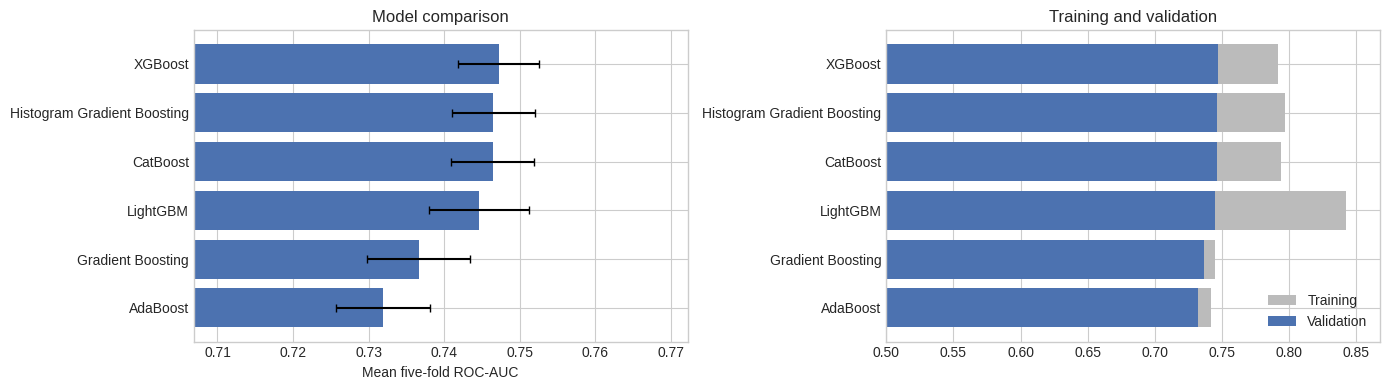

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, max(4, len(summary) * .4)))
order = summary.sort_values('ROC-AUC')
axes[0].barh(order.Trial, order['ROC-AUC'], xerr=order.Std, color='#4C72B0', capsize=3)
axes[0].set_xlim(max(.5, order['ROC-AUC'].min() - .025), min(1, order['ROC-AUC'].max() + .025))
axes[0].set_xlabel('Mean five-fold ROC-AUC')
axes[0].set_title('Model comparison')
axes[1].barh(order.Trial, order['Train ROC-AUC'], color='#BBBBBB', label='Training')
axes[1].barh(order.Trial, order['ROC-AUC'], color='#4C72B0', label='Validation')
axes[1].set_xlim(.5, min(1, order['Train ROC-AUC'].max() + .025))
axes[1].set_title('Training and validation')
axes[1].legend()
fig.tight_layout()
plt.show()


## What changed

Six boosting models were tested on the same features. XGBoost had the highest ROC-AUC, so it was selected for the final model.


## ROC Curves

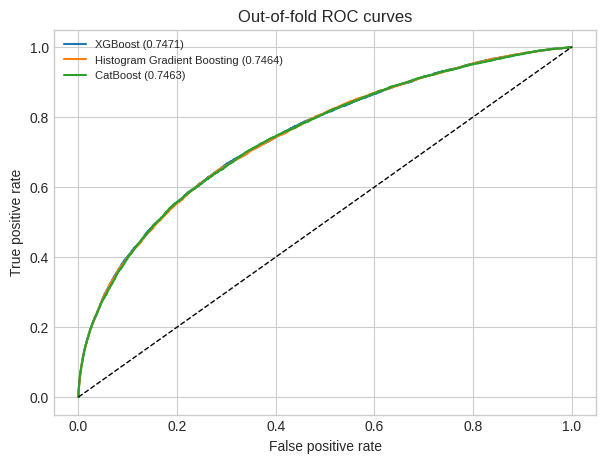

In [26]:
fig, ax = plt.subplots(figsize=(7, 5))
for name in summary.Trial.head(3):
    fpr, tpr, _ = roc_curve(y, oof[name])
    ax.plot(fpr, tpr, label=f'{name} ({roc_auc_score(y, oof[name]):.4f})')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1)
ax.set(xlabel='False positive rate', ylabel='True positive rate', title='Out-of-fold ROC curves')
ax.legend(fontsize=8)
plt.show()


The table reports the mean of five fold ROC-AUCs. The ROC legend uses all out-of-fold predictions together, so the numbers can differ slightly.

## Final Model and Submission

The chosen booster is fit five times, once on each four-fifths of the labeled stays. Each fit scores the test stays, and those five probabilities are averaged. The averaged values are written in the sample-submission order.

In [27]:
best = summary.iloc[0]
best_name = best.Trial
best_spec = copy.deepcopy(TRIALS[best_name])
final_frame = views[best_spec['view']]
labeled = final_frame.loc[y.index]
unlabeled = final_frame.loc[test.encounter_id]
fold_predictions = []
selected_columns = None
submission_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
with threadpool_limits(limits=JOBS):
    for fit_positions, _ in submission_folds.split(labeled, y):
        probability, _, _, _, selected_columns = fit_predict(
            best_spec, labeled.iloc[fit_positions], y.iloc[fit_positions], unlabeled)
        fold_predictions.append(probability)
test_probability = np.mean(fold_predictions, axis=0)
submission = pd.DataFrame({'encounter_id': test.encounter_id.to_numpy(), 'readmit_30d': test_probability})
sample = pd.read_csv(DATA_DIR / 'sample_submission.csv')
submission = submission.set_index('encounter_id').loc[sample.encounter_id].reset_index()
assert submission.encounter_id.equals(sample.encounter_id)
assert submission.readmit_30d.between(0, 1).all()
submission.to_csv(OUTPUT_DIR / 'submission.csv', index=False)
pd.DataFrame({'feature': selected_columns}).to_csv(OUTPUT_DIR / 'final_columns.csv', index=False)
selected = {'stage': STAGE, 'stage_name': STAGE_NAME, 'trial': best_name,
            'spec': best_spec, 'cv_roc_auc': float(best['ROC-AUC']),
            'cv_std': float(best.Std), 'accuracy': float(best.Accuracy),
            'previous_cv': PREVIOUS_CV, 'base_view': BASE_VIEW,
            'user_supplied_previous_submission_score': .74497, 'new_public_score': None,
            'validation': 'Five-fold stratified CV, shuffle=True, seed=42. CV also selects trials; it is a development estimate.',
            'prediction': 'Average of five boosters, each fit on four of the five training folds.'}
(OUTPUT_DIR / 'selected_model.json').write_text(json.dumps(selected, indent=2))
(OUTPUT_DIR / 'data_quality.json').write_text(json.dumps(quality, indent=2))
print('Selected:', best_name)
print('Mean CV ROC-AUC:', f'{best["ROC-AUC"]:.5f}')
print('Input features:', len(selected_columns))
print('Submission rows:', len(submission))
print('Saved: submission.csv')
display(submission.head())


Selected: XGBoost
Mean CV ROC-AUC: 0.74719
Input features: 346
Submission rows: 32812
Saved: submission.csv


,encounter_id,readmit_30d
0,E14322700,0.058191
1,E10891017,0.105527
2,E15846764,0.086926
3,E35399048,0.091815
4,E18403456,0.030586
